<div style="background-color:Gold; color:black; padding:20px; border-left:6px solid brown; border-radius:10px;text-align: center">
    <h1><b>World Happiness Reports: 2015–2019</b></h1>
    <h3 style="font-weight:normal;"><b>Interactive Dashboard Project</b></h3>
    <h2><b>🎓 Maliheh Mahdavi Sefat - ID11408 </b></h2> 
        <p>University of Minho</p>
        <p>School of Management, Economics, and Political Science</p>
        <p>November 2026</p>
</div>


<div style="background-color:#145A32; color:white; padding:20px; border-left:6px solid LimeGreen;border-radius:10px;">
    <p>
        This project examines how happiness scores and their associated
        economic, social, health, freedom, generosity, and
        corruption-perception indicators vary across countries and over time.
    </p>
</div>
<div style="background-color:LemonChiffon; color:black; padding:20px; border-left:6px solid brown; border-radius:10px;">    
    <h2>Research Questions</h2>
    <ul>
        <li>Which countries have the highest happiness scores?</li>
        <li>How is GDP per capita associated with happiness?</li>
        <li>How is social support associated with happiness?</li>
        <li>How are health and freedom associated with happiness?</li>
        <li>How are perceptions of corruption associated with happiness?</li>
    </ul>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <h2>Happiness Report</h2>
    <p>
        Happiness rankings do not directly measure how often people laugh or
        experience momentary pleasure. This project examines the broader
        economic, social, health, freedom, generosity, and corruption-related
        indicators associated with national happiness scores.
    </p>
    <p>
        The dashboard will allow users to filter countries, compare indicators,
        inspect relationships, and explore the underlying data interactively.
    </p>
</div>

<div style="background-color:coral; color:black; padding:20px; border-left:6px solid red; border-radius:10px;">
    <h2>1 - Import Libraries</h2>
</div>

In [3]:
# -------------------------------------------------------------
# IMPORT LIBRARIES
# -------------------------------------------------------------

# Operating system utilities
import os

# Numerical computing
import numpy as np

# Data manipulation and analysis
import pandas as pd

# Static visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive visualizations
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Dash dashboard components
import dash
from dash import html, dcc, dash_table, Input, Output

# Notebook display utilities
from IPython.display import HTML, display

# String similarity matching
from difflib import SequenceMatcher

# Country flag generation
import countryflag

<div style="background-color:#F4F6F7; color:#17202A; padding:18px; border-left:6px solid #7F8C8D; border-radius:10px;">
    <h3>Optional: Google Colab Setup</h3>
    <p>
        The following cell is required only when the notebook and dataset are
        stored in Google Drive and the project is being run in Google Colab.
        It is not needed in a local Jupyter Notebook.
    </p>
</div>

In [4]:
# Run this cell only in Google Colab.

# from google.colab import drive
# import os

# Mount Google Drive.
# drive.mount("/content/drive")

# Move to the folder containing the notebook and dataset.
# Replace the folder path with your actual folder.
# os.chdir("/content/drive/MyDrive/Dashboard_Python")

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>2 - Load the Dataset</h2>
    Download from Kaggle: 
</div>

In [5]:
# -------------------------------------------------------------
# LOAD THE DATASET
# -------------------------------------------------------------

# Read the 2019 World Happiness Report CSV file.
df = pd.read_csv("2019.csv")

# Display the first five rows to confirm that the file loaded correctly.
df.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>3 - Load and Inspect the Annual Datasets</h2>
    Download from Kaggle: <a href="https://www.kaggle.com/datasets/unsdsn/world-happiness">World Happiness Report</a>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The project uses the World Happiness Report datasets from 2015 to 2019.
        Before combining the files, each dataset is loaded separately so that
        differences in column names and structure can be identified.
    </p>
</div>

In [6]:
# -------------------------------------------------------------
# LOAD EACH YEAR AS A SEPARATE DATAFRAME
# -------------------------------------------------------------

# The five CSV files must be in the same folder as this notebook.
df_2015 = pd.read_csv("2015.csv")
df_2016 = pd.read_csv("2016.csv")
df_2017 = pd.read_csv("2017.csv")
df_2018 = pd.read_csv("2018.csv")
df_2019 = pd.read_csv("2019.csv")


# -------------------------------------------------------------
# DISPLAY THE SHAPE AND COLUMN NAMES OF EACH DATAFRAME
# -------------------------------------------------------------

# Store the dataframes in a dictionary so that they can be
# inspected efficiently without repeating the same commands.
yearly_data = {
    2015: df_2015,
    2016: df_2016,
    2017: df_2017,
    2018: df_2018,
    2019: df_2019
}

# Print the dimensions and column names for every year.
for year, data in yearly_data.items():
    print(f"\n{'=' * 60}")
    print(f"YEAR: {year}")
    print(f"Rows and columns: {data.shape}")
    print("Column names:")
    
    for column in data.columns:
        print(f"  - {column}")


YEAR: 2015
Rows and columns: (158, 12)
Column names:
  - Country
  - Region
  - Happiness Rank
  - Happiness Score
  - Standard Error
  - Economy (GDP per Capita)
  - Family
  - Health (Life Expectancy)
  - Freedom
  - Trust (Government Corruption)
  - Generosity
  - Dystopia Residual

YEAR: 2016
Rows and columns: (157, 13)
Column names:
  - Country
  - Region
  - Happiness Rank
  - Happiness Score
  - Lower Confidence Interval
  - Upper Confidence Interval
  - Economy (GDP per Capita)
  - Family
  - Health (Life Expectancy)
  - Freedom
  - Trust (Government Corruption)
  - Generosity
  - Dystopia Residual

YEAR: 2017
Rows and columns: (155, 12)
Column names:
  - Country
  - Happiness.Rank
  - Happiness.Score
  - Whisker.high
  - Whisker.low
  - Economy..GDP.per.Capita.
  - Family
  - Health..Life.Expectancy.
  - Freedom
  - Generosity
  - Trust..Government.Corruption.
  - Dystopia.Residual

YEAR: 2018
Rows and columns: (156, 9)
Column names:
  - Overall rank
  - Country or region
  -

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>4 - Understand and Harmonize the Variables</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The annual datasets contain the same main concepts, but some variable
        names changed between 2015 and 2019. Before combining the files, the
        meaning of each shared variable must be clarified.
    </p>
    <p>
        The variables following the happiness score are explanatory factors
        used by the World Happiness Report to explain differences in national
        life evaluations. They should not be interpreted as separate direct
        measures of happiness or as proof of causal effects.
    </p>
</div>

<div style="background-color:AliceBlue; color:black; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>Meaning of the Shared Variables</h3>
    <p>
        <b>Country:</b> The country or territory represented by the observation.
    </p>
    <p>
        <b>Year:</b> The edition year of the World Happiness Report dataset.
        This variable will be added before the annual files are combined.
    </p>
    <p>
        <b>Rank (1–N; 1 is the highest):</b> The country's position in the happiness ranking for that
        report year. A lower numerical rank indicates a higher position.
    </p>
    <p>
        <b>Happiness Score (0–10; 10 is the highest):</b> A national life-evaluation score based on the
        Cantril Ladder. Respondents evaluate their current lives on a scale from
        0, representing the worst possible life, to 10, representing the best
        possible life.
    </p>
    <p>
        <b>GDP per Capita (derived contribution; higher is better):</b> An economic indicator based on GDP per person,
        adjusted for differences in purchasing power between countries.
    </p>
    <p>
        <b>Family or Social Support (derived contribution; higher is better):</b> The national average response to a question asking
        whether people have relatives or friends they can count on for help when
        they are in trouble.
    </p>
    <p>
        <b>Healthy Life Expectancy (derived contribution; higher is better):</b> The expected number of years that people
        can live in good health, based on World Health Organization data.
    </p>
    <p>
        <b>Freedom (derived contribution; higher is better):</b> The national average response to a question asking
        whether people are satisfied with their freedom to choose what they do
        with their lives.
    </p>
    <p>
        <b>Generosity (derived contribution; higher indicates more generosity):</b> A measure based on whether respondents donated money
        to charity during the previous month, adjusted for GDP per capita.
    </p>
    <p>
        <b>Trust or Corruption_Perception (derived contribution; higher is better):</b> A measure based on respondents'
        perceptions of whether corruption is widespread in government and
        business. Indicates trusting the system.
    </p>
</div>

<div style="background-color:LemonChiffon; color:#281201; padding:20px; border-left:6px solid Gold; border-radius:10px;">
    <h3>Why Is “Family” Renamed “Social Support”?</h3>
    <p>
        In the 2015, 2016, and 2017 datasets, the social-support variable is
        labelled <b>Family</b>. In the 2018 and 2019 datasets, the corresponding
        variable is labelled <b>Social support</b>.
    </p>
    <p>
        The measure is not limited to family relationships. It asks whether
        respondents have relatives or friends they can count on for help when
        they are in trouble. Therefore, <b>Social Support</b> is the clearer and
        more accurate common name.
    </p>
    <p>
        The columns <b>Family</b> and <b>Social support</b> will consequently be
        harmonized as <b>Social_Support</b> before stacking the annual datasets.
    </p>
</div>

<div style="background-color:MistyRose; color:#641E16; padding:20px; border-left:6px solid IndianRed; border-radius:10px;">
    <h3>Variables Excluded from the Combined Dataset</h3>
    <p>
        Only variables available with an equivalent meaning in all five annual
        files will be retained.
    </p>
    <ul>
        <li>
            <b>Region</b> is excluded because it is not included in every annual
            file.
        </li>
        <li>
            <b>Standard Error, confidence intervals, and whisker variables</b>
            are excluded because their structures differ across years and they
            are absent from the 2018 and 2019 files.
        </li>
        <li>
            <b>Dystopia Residual</b> is excluded because it is absent from the
            2018 and 2019 files.
        </li>
    </ul>
    <p>
        The combined dataset will retain Country, Year, Rank, Happiness Score,
        GDP, Social Support, Healthy Life Expectancy, Freedom, Generosity, and
        Perceptions of Corruption.
    </p>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>5 - Standardize and Combine the Annual Datasets</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The annual files use different column names for equivalent variables.
        The relevant columns are renamed consistently, and variables that are
        not shared across all five years are excluded.
    </p>
    <p>
        A Year column is added before stacking the datasets. The resulting
        dataset contains one row for each country-year observation.
    </p>
</div>

In [7]:
# -------------------------------------------------------------
# STANDARDIZE THE 2015 DATASET
# -------------------------------------------------------------

df_2015_clean = df_2015.rename(columns={
    "Country": "Country",
    "Happiness Rank": "Rank",
    "Happiness Score": "Happiness_Score",
    "Economy (GDP per Capita)": "GDP",
    "Family": "Social_Support",
    "Health (Life Expectancy)": "Life_Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust (Government Corruption)": "Trust"
})

# Add the report year before combining the datasets.
df_2015_clean["Year"] = 2015


# -------------------------------------------------------------
# STANDARDIZE THE 2016 DATASET
# -------------------------------------------------------------

df_2016_clean = df_2016.rename(columns={
    "Country": "Country",
    "Happiness Rank": "Rank",
    "Happiness Score": "Happiness_Score",
    "Economy (GDP per Capita)": "GDP",
    "Family": "Social_Support",
    "Health (Life Expectancy)": "Life_Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust (Government Corruption)": "Trust"
})

df_2016_clean["Year"] = 2016


# -------------------------------------------------------------
# STANDARDIZE THE 2017 DATASET
# -------------------------------------------------------------

df_2017_clean = df_2017.rename(columns={
    "Country": "Country",
    "Happiness.Rank": "Rank",
    "Happiness.Score": "Happiness_Score",
    "Economy..GDP.per.Capita.": "GDP",
    "Family": "Social_Support",
    "Health..Life.Expectancy.": "Life_Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust..Government.Corruption.": "Trust"
})

df_2017_clean["Year"] = 2017


# -------------------------------------------------------------
# STANDARDIZE THE 2018 DATASET
# -------------------------------------------------------------

df_2018_clean = df_2018.rename(columns={
    "Country or region": "Country",
    "Overall rank": "Rank",
    "Score": "Happiness_Score",
    "GDP per capita": "GDP",
    "Social support": "Social_Support",
    "Healthy life expectancy": "Life_Expectancy",
    "Freedom to make life choices": "Freedom",
    "Generosity": "Generosity",
    "Perceptions of corruption": "Trust"
})

df_2018_clean["Year"] = 2018


# -------------------------------------------------------------
# STANDARDIZE THE 2019 DATASET
# -------------------------------------------------------------

df_2019_clean = df_2019.rename(columns={
    "Country or region": "Country",
    "Overall rank": "Rank",
    "Score": "Happiness_Score",
    "GDP per capita": "GDP",
    "Social support": "Social_Support",
    "Healthy life expectancy": "Life_Expectancy",
    "Freedom to make life choices": "Freedom",
    "Generosity": "Generosity",
    "Perceptions of corruption": "Trust"
})

df_2019_clean["Year"] = 2019


# -------------------------------------------------------------
# KEEP ONLY THE SHARED VARIABLES
# -------------------------------------------------------------

shared_columns = [
    "Country",
    "Year",
    "Rank",
    "Happiness_Score",
    "GDP",
    "Social_Support",
    "Life_Expectancy",
    "Freedom",
    "Generosity",
    "Trust"
]

df_2015_clean = df_2015_clean[shared_columns]
df_2016_clean = df_2016_clean[shared_columns]
df_2017_clean = df_2017_clean[shared_columns]
df_2018_clean = df_2018_clean[shared_columns]
df_2019_clean = df_2019_clean[shared_columns]


# -------------------------------------------------------------
# STACK THE FIVE DATASETS
# -------------------------------------------------------------

happiness = pd.concat(
    [
        df_2015_clean,
        df_2016_clean,
        df_2017_clean,
        df_2018_clean,
        df_2019_clean
    ],
    ignore_index=True
)


# -------------------------------------------------------------
# VERIFY THE COMBINED DATASET
# -------------------------------------------------------------

print("Combined dataset dimensions:", happiness.shape)
print("\nColumns:")
print(happiness.columns.tolist())

# Display the first five country-year observations.
happiness.head(10)

Combined dataset dimensions: (782, 10)

Columns:
['Country', 'Year', 'Rank', 'Happiness_Score', 'GDP', 'Social_Support', 'Life_Expectancy', 'Freedom', 'Generosity', 'Trust']


,Country,Year,Rank,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Trust
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957
5,Finland,2015,6,7.406,1.29025,1.31826,0.88911,0.64169,0.23351,0.41372
6,Netherlands,2015,7,7.378,1.32944,1.28017,0.89284,0.61576,0.47610,0.31814
7,Sweden,2015,8,7.364,1.33171,1.28907,0.91087,0.65980,0.36262,0.43844
8,New Zealand,2015,9,7.286,1.25018,1.31967,0.90837,0.63938,0.47501,0.42922
9,Australia,2015,10,7.284,1.33358,1.30923,0.93156,0.65124,0.43562,0.35637


<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>6 - Inspect Missing Values</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The combined dataset contains 782 country-year observations.
        All variables are complete except Trust, which has one missing value.
        The affected observation is inspected before deciding how to handle it.
    </p>
</div>

In [8]:
# -------------------------------------------------------------
# INPECT NULL VALUES AND DATATYPE
# -------------------------------------------------------------
happiness.info()

<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Country          782 non-null    str    
 1   Year             782 non-null    int64  
 2   Rank             782 non-null    int64  
 3   Happiness_Score  782 non-null    float64
 4   GDP              782 non-null    float64
 5   Social_Support   782 non-null    float64
 6   Life_Expectancy  782 non-null    float64
 7   Freedom          782 non-null    float64
 8   Generosity       782 non-null    float64
 9   Trust            781 non-null    float64
dtypes: float64(7), int64(2), str(1)
memory usage: 61.2 KB


In [9]:
# -------------------------------------------------------------
# INSPECT THE MISSING VALUE
# -------------------------------------------------------------

# Count missing values in each column.
print("Missing values by column:")
display(happiness.isna().sum().to_frame(name="Missing_Count"))

# Display the complete observation containing the missing value.
missing_trust = happiness[happiness["Trust"].isna()]

print("Observation with missing Trust value:")
display(missing_trust)

Missing values by column:


,Missing_Count
Country,0
Year,0
Rank,0
Happiness_Score,0
GDP,0
Social_Support,0
Life_Expectancy,0
Freedom,0
Generosity,0
Trust,1


Observation with missing Trust value:


,Country,Year,Rank,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Trust
489,United Arab Emirates,2018,20,6.774,2.096,0.776,0.67,0.284,0.186,NaN


<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>7 - Impute the Missing Trust Value</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The only missing value is the 2018 Trust value for the United Arab Emirates.
        Because 2018 lies between two available observations, the
        missing value is estimated by linear interpolation between the country's
        2017 and 2019 Trust values.
    </p>
</div>

In [10]:
# -------------------------------------------------------------
# IMPUTE THE MISSING TRUST VALUE BY LINEAR INTERPOLATION
# -------------------------------------------------------------

# Display the UAE observations before imputation.
uae_before = happiness.loc[
    happiness["Country"] == "United Arab Emirates",
    ["Country", "Year", "Trust"]
].sort_values("Year")

print("UAE Trust values before interpolation:")
display(uae_before)


# Create a condition identifying all UAE observations.
uae_mask = happiness["Country"] == "United Arab Emirates"

# Sort the UAE observations by year.
uae_sorted = happiness.loc[uae_mask].sort_values("Year")

# Estimate the missing internal value using the values immediately
# before and after it in the time series.
uae_sorted["Trust"] = uae_sorted["Trust"].interpolate(method="linear")

# Copy the interpolated Trust values back to the main dataframe.
happiness.loc[uae_sorted.index, "Trust"] = uae_sorted["Trust"]


# -------------------------------------------------------------
# VERIFY THE RESULT
# -------------------------------------------------------------

uae_after = happiness.loc[
    happiness["Country"] == "United Arab Emirates",
    ["Country", "Year", "Trust"]
].sort_values("Year")

print("UAE Trust values after interpolation:")
display(uae_after)

print("\nRemaining missing values:", happiness.isna().sum().sum())

UAE Trust values before interpolation:


,Country,Year,Trust
19,United Arab Emirates,2015,0.38583
185,United Arab Emirates,2016,0.35561
335,United Arab Emirates,2017,0.32449
489,United Arab Emirates,2018,NaN
646,United Arab Emirates,2019,0.18200


UAE Trust values after interpolation:


,Country,Year,Trust
19,United Arab Emirates,2015,0.385830
185,United Arab Emirates,2016,0.355610
335,United Arab Emirates,2017,0.324490
489,United Arab Emirates,2018,0.253245
646,United Arab Emirates,2019,0.182000



Remaining missing values: 0


<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>8 - Inspect Country-Name Consistency</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        Country names must be consistent before creating country filters,
        trend charts, and maps. First, the existing names and the number of
        years in which each name appears are inspected. Possible variations
        are standardized only after they have been identified.
    </p>
</div>

In [11]:
# -------------------------------------------------------------
# INSPECT COUNTRY NAMES ACROSS YEARS
# -------------------------------------------------------------

# Count how many distinct report years are available for each
# country name.
country_year_counts = (
    happiness.groupby("Country")["Year"]
    .nunique()
    .sort_values()
    .reset_index(name="Number_of_Years")
)

# Show names that occur in fewer than all five years.
# This list can contain:
# 1. Genuine countries included only in some reports
# 2. Different spellings or names for the same place
countries_under_five_years = country_year_counts[
    country_year_counts["Number_of_Years"] < 5
]

print("Country names appearing in fewer than five years:")
display(countries_under_five_years)

print(
    "Number of country names appearing in fewer than five years:",
    len(countries_under_five_years)
)

Country names appearing in fewer than five years:


,Country,Number_of_Years
0,Gambia,1
1,"Hong Kong S.A.R., China",1
2,Djibouti,1
3,Oman,1
4,Puerto Rico,1
5,North Macedonia,1
6,Somaliland region,1
7,Somaliland Region,1
8,Taiwan Province of China,1
9,Swaziland,2


Number of country names appearing in fewer than five years: 29


In [12]:
# Show names that occur in  all five years.

countries_under_five_years = country_year_counts[
    country_year_counts["Number_of_Years"] == 5
]

print("Country names appearing in fewer than five years:")
display(countries_under_five_years)

print(
    "Number of country names appearing in fewer than five years:",
    len(countries_under_five_years)
)

Country names appearing in fewer than five years:


,Country,Number_of_Years
29,Bulgaria,5
30,Bhutan,5
31,Benin,5
32,Colombia,5
33,China,5
...,...,...
165,Venezuela,5
166,Vietnam,5
167,Yemen,5
168,Zambia,5


Number of country names appearing in fewer than five years: 141


In [13]:
# -------------------------------------------------------------
# DISPLAY COUNTRY NAMES BY YEAR
# -------------------------------------------------------------

for year in sorted(happiness["Year"].unique()):
    
    countries = sorted(
        happiness.loc[happiness["Year"] == year, "Country"].unique()
    )
    
    print(f"\n{'=' * 60}")
    print(f"YEAR: {year}")
    print(f"Number of country names: {len(countries)}")
    print(countries)


YEAR: 2015
Number of country names: 158
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo (Brazzaville)', 'Congo (Kinshasa)', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Finland', 'France', 'Gabon', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Haiti', 'Honduras', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Laos', 'Latvia', 'Lebanon', 'Lesotho', 'Liberia', 'Lib


<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
Simple fuzzy matching can produce false
        candidates, such as Australia and Austria or Niger and Nigeria.
    </p>
    <p>
        To reduce false matches, names are compared only when they do not occur
        in the same report year. Possible variations are then identified using
        both text containment and fuzzy similarity. The resulting candidates
        are manually reviewed before any names are changed.
    </p>
</div>

In [14]:
# -------------------------------------------------------------
# FIND POSSIBLE COUNTRY-NAME VARIATIONS PYTHONIC WAY
# -------------------------------------------------------------

from difflib import SequenceMatcher
import pandas as pd

# Create one sorted list containing every distinct country name.
country_names = sorted(happiness["Country"].dropna().unique())

possible_matches = []

# Compare every country name with the names that follow it.
for i, name_1 in enumerate(country_names):
    for name_2 in country_names[i + 1:]:
        
        # Calculate text similarity between 0 and 1.
        similarity = SequenceMatcher(
            None,
            name_1.lower(),
            name_2.lower()
        ).ratio()
        
        # Retain only relatively similar pairs.
        # A threshold of 0.67 creates suggestions rather than
        # automatically treating the names as equivalent.
        if similarity >= 0.67:
            possible_matches.append({
                "Country_Name_1": name_1,
                "Country_Name_2": name_2,
                "Similarity": round(similarity, 3)
            })

# Convert the candidate pairs into a dataframe.
possible_matches_df = pd.DataFrame(possible_matches)

# Show the strongest similarities first.
possible_matches_df = possible_matches_df.sort_values(
    "Similarity",
    ascending=False
).reset_index(drop=True)

display(possible_matches_df)

,Country_Name_1,Country_Name_2,Similarity
0,Somaliland Region,Somaliland region,1.000
1,North Cyprus,Northern Cyprus,0.889
2,Trinidad & Tobago,Trinidad and Tobago,0.889
3,Australia,Austria,0.875
4,Iceland,Ireland,0.857
5,Niger,Nigeria,0.833
6,Gambia,Zambia,0.833
7,Malawi,Mali,0.800
8,Pakistan,Tajikistan,0.778
9,Namibia,Zambia,0.769


In [15]:
# -------------------------------------------------------------
# IDENTIFY POSSIBLE COUNTRY-NAME VARIATIONS
# -------------------------------------------------------------

from difflib import SequenceMatcher
import pandas as pd
import re


# -------------------------------------------------------------
# HELPER FUNCTION: NORMALIZE A NAME FOR TEXT COMPARISON
# -------------------------------------------------------------

def normalize_country_name(name):
    """
    Prepare a country name for comparison without changing
    the original value stored in the dataframe.
    """
    
    # Convert to lowercase.
    name = name.lower()
    
    # Replace "&" with "and" so that:
    # "Trinidad & Tobago" and "Trinidad and Tobago" can match.
    name = name.replace("&", "and")
    
    # Remove punctuation and replace it with spaces.
    name = re.sub(r"[^a-z0-9\s]", " ", name)
    
    # Replace repeated spaces with one space.
    name = re.sub(r"\s+", " ", name).strip()
    
    return name


# -------------------------------------------------------------
# RECORD THE YEARS ASSOCIATED WITH EACH COUNTRY NAME
# -------------------------------------------------------------

# Example:
# "Hong Kong" -> {2015, 2016, 2018, 2019}
# "Hong Kong S.A.R., China" -> {2017}
country_year_sets = (
    happiness.groupby("Country")["Year"]
    .apply(set)
    .to_dict()
)

country_names = sorted(country_year_sets.keys())

possible_matches = []


# -------------------------------------------------------------
# COMPARE COUNTRY NAMES
# -------------------------------------------------------------

for i, name_1 in enumerate(country_names):
    for name_2 in country_names[i + 1:]:
        
        years_1 = country_year_sets[name_1]
        years_2 = country_year_sets[name_2]
        
        # If both names occur in the same year, they almost certainly represent different countries or territories.
        #
        # This excludes false candidates such as:
        # Australia / Austria
        # Niger / Nigeria
        # Sudan / South Sudan
        if not years_1.isdisjoint(years_2):
            continue
        
        normalized_1 = normalize_country_name(name_1)
        normalized_2 = normalize_country_name(name_2)
        
        # Calculate character-based fuzzy similarity.
        similarity = SequenceMatcher(
            None,
            normalized_1,
            normalized_2,
            autojunk=False
        ).ratio()
        
        # Check whether the shorter complete name occurs inside the longer name.
        #
        # This can identify:
        # "Hong Kong" inside "Hong Kong S A R China"
        # "Taiwan" inside "Taiwan Province of China"
        containment_match = (
            normalized_1 in normalized_2 or
            normalized_2 in normalized_1
        )
        
        # Retain a pair when:
        # 1. One normalized name contains the other, or
        # 2. Their fuzzy similarity is sufficiently high.
        if containment_match or similarity >= 0.65:
            possible_matches.append({
                "Country_Name_1": name_1,
                "Years_Name_1": sorted(years_1),
                "Country_Name_2": name_2,
                "Years_Name_2": sorted(years_2),
                "Containment_Match": containment_match,
                "Similarity": round(similarity, 3)
            })


# -------------------------------------------------------------
# DISPLAY THE CANDIDATE PAIRS
# -------------------------------------------------------------

possible_matches_df = pd.DataFrame(possible_matches)

if possible_matches_df.empty:
    print("No possible naming variations were identified.")

else:
    # Show containment matches first, followed by fuzzy similarity.
    possible_matches_df = possible_matches_df.sort_values(
        by=["Containment_Match", "Similarity"],
        ascending=[False, False]
    ).reset_index(drop=True)
    
    display(possible_matches_df)

,Country_Name_1,Years_Name_1,Country_Name_2,Years_Name_2,Containment_Match,Similarity
0,Somaliland Region,[2016],Somaliland region,[2015],True,1.000
1,Trinidad & Tobago,"[2018, 2019]",Trinidad and Tobago,"[2015, 2016, 2017]",True,1.000
2,Macedonia,"[2015, 2016, 2017, 2018]",North Macedonia,[2019],True,0.750
3,Hong Kong,"[2015, 2016, 2018, 2019]","Hong Kong S.A.R., China",[2017],True,0.600
4,Taiwan,"[2015, 2016, 2018, 2019]",Taiwan Province of China,[2017],True,0.400
5,North Cyprus,"[2015, 2016, 2017]",Northern Cyprus,"[2018, 2019]",False,0.889


<div style="background-color:AliceBlue; color:black; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>Interpretation of the Name Inspection</h3>
    <p>
        The automated procedure produces candidate name variations rather than
        changing the data automatically. Names that occur in the same year are
        excluded because they normally represent distinct countries or
        territories.
    </p>
    <p>
        Text containment helps identify cases in which one report uses a longer
        name, such as Hong Kong S.A.R., China, while another uses Hong Kong.
        Fuzzy similarity helps identify spelling and formatting variations.
    </p>
    <p>
        The candidate pairs must still be reviewed manually. This prevents
        genuinely different countries with similar names from being combined.
    </p>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red;border-radius:10px;">
    <h2>9 - Standardize Country Names</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        Some countries have different names across the annual datasets.
        These variations are standardized so that each country appears as one
        category in filters, trend charts, summary statistics, and maps.
    </p>
</div>

In [16]:
# -------------------------------------------------------------
# STANDARDIZE COUNTRY NAMES
# -------------------------------------------------------------

# Remove accidental spaces at the beginning or end of country names.
happiness["Country"] = happiness["Country"].str.strip()

# Different annual reports sometimes use different names for the
# same country or territory. This dictionary defines one common name
# for each known variation.
country_name_mapping = {
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong",
    "North Cyprus": "Northern Cyprus",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Macedonia": "North Macedonia",
    "Somaliland region": "Somaliland Region"
}

# Replace the inconsistent names with the selected common names.
happiness["Country"] = happiness["Country"].replace(country_name_mapping)


# -------------------------------------------------------------
# VERIFY THE CHANGES
# -------------------------------------------------------------

# Display the standardized records for the affected countries.
standardized_names = [
    "Taiwan",
    "Hong Kong",
    "Northern Cyprus",
    "Trinidad and Tobago",
    "North Macedonia",
    "Somaliland Region",
    "Eswatini"
]

display(
    happiness[happiness["Country"].isin(standardized_names)]
    [["Country", "Year", "Rank", "Happiness_Score"]]
    .sort_values(["Country", "Year"])
)

# Display the total number of unique country names.
print("Number of unique country names:", happiness["Country"].nunique())

# -------------------------------------------------------------
# SAVE THE CLEANED COMMULATIVE DATASET
# -------------------------------------------------------------

happiness.to_csv('happiness15-19.csv')

,Country,Year,Rank,Happiness_Score
71,Hong Kong,2015,72,5.474
232,Hong Kong,2016,75,5.458
385,Hong Kong,2017,71,5.472
545,Hong Kong,2018,76,5.430
701,Hong Kong,2019,76,5.430
92,North Macedonia,2015,93,5.007
252,North Macedonia,2016,95,5.121
406,North Macedonia,2017,92,5.175
558,North Macedonia,2018,89,5.185
709,North Macedonia,2019,84,5.274


Number of unique country names: 164


<div style="background-color:AliceBlue; color:black; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>Country-Name Standardization Result</h3>
     <p>
        Six naming variations were identified and standardized. Only names
        that referred to the same country or territory under different labels
        in the annual files were changed.
    </p>
    <p>
        Countries unavailable in some report years were retained in the
        dataset. No artificial country-year rows or placeholder values were
        added. Visualizations will distinguish between recorded observations
        and years for which a country was not included.
    </p>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>10 - Create an Interactive and Animated Happiness Map</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The interactive map displays the geographic distribution of happiness
        scores from 2015 to 2019. Countries are colored according to their
        happiness scores, while the hover information shows the country,
        report year, score, and rank.
    </p>
    <p>
        The animation controls allow the user to move between report years.
        Countries that were not included in a particular annual report are
        left uncolored rather than being assigned artificial values.
    </p>
</div>

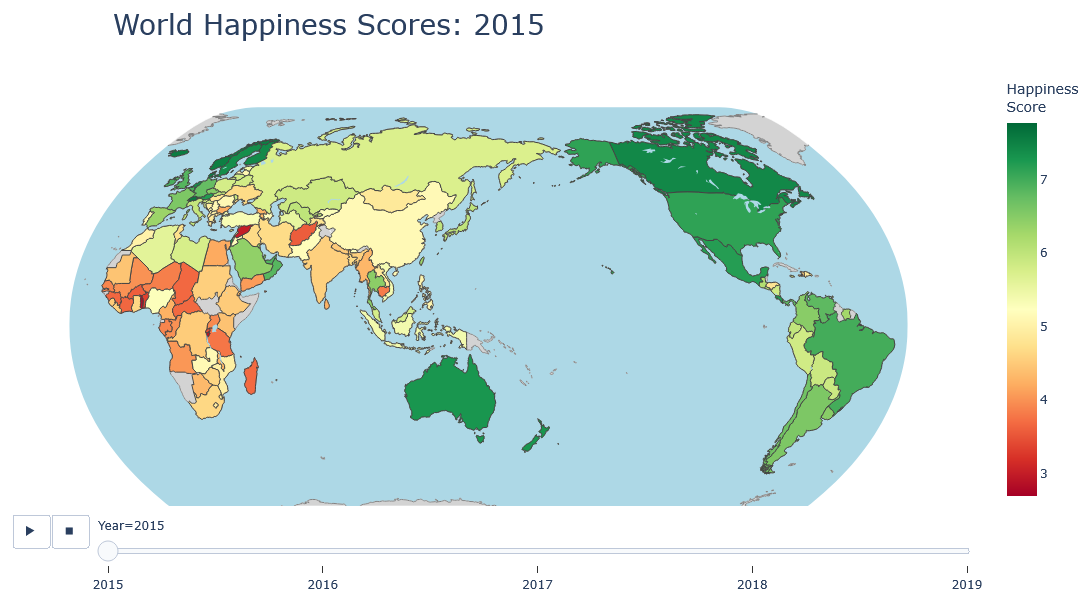

In [17]:
# -------------------------------------------------------------
# CREATE AN INTERACTIVE, ANIMATED, LOOPING WORLD MAP
# -------------------------------------------------------------

import plotly.express as px
import plotly.io as pio
from IPython.display import HTML, display


# Sort observations chronologically.
map_data = happiness.sort_values(
    ["Year", "Country"]
).copy()


# Use one fixed color range across all years.
# This ensures that the same score always has the same color.
minimum_score = map_data["Happiness_Score"].min()
maximum_score = map_data["Happiness_Score"].max()


# -------------------------------------------------------------
# CREATE THE BASIC ANIMATED MAP
# -------------------------------------------------------------

animated_map = px.choropleth(
    map_data,

    # Identify geographic areas using country names.
    locations="Country",
    locationmode="country names",

    # Color countries using their happiness scores.
    color="Happiness_Score",

    # Show the country name at the top of the hover label.
    hover_name="Country",

    # Select the additional information shown on hover.
    hover_data={
        "Year": False,
        "Rank": True,
        "Happiness_Score": ":.3f",
        "GDP": False,
        "Social_Support": False,
        "Life_Expectancy": False,
        "Freedom": False,
        "Generosity": False,
        "Trust": False
    },

    # Create one frame for each report year.
    animation_frame="Year",
    animation_group="Country",

    # Preserve the meaning of colors across all frames.
    range_color=(minimum_score, maximum_score),
    color_continuous_scale="RdYlGn",

    labels={
        "Happiness_Score": "Happiness Score",
        "Rank": "Rank"
    },

    projection="natural earth"
)


# -------------------------------------------------------------
# ADD A DIFFERENT TITLE TO EACH FRAME
# -------------------------------------------------------------

for frame in animated_map.frames:
    year = frame.name

    frame.layout.update(
        title={
            "text": f"World Happiness Scores: {year}",
            "x": 0.5,
            "xanchor": "right",
            "font": {
                "size": 28
            }
        }
    )


# Set the title displayed before the animation starts.
first_year = int(map_data["Year"].min())

animated_map.update_layout(
    title={
        "text": f"World Happiness Scores: {first_year}",
        "x": 0.5,
        "xanchor": "right",
        "font": {
            "size": 28
        }
    }
)


# -------------------------------------------------------------
# FORMAT LAND, OCEANS, LAKES, AND BORDERS
# -------------------------------------------------------------

animated_map.update_geos(
    # Display oceans with a blue background.
    showocean=True,
    oceancolor="LightBlue",

    # Display lakes using the same blue family.
    showlakes=True,
    lakecolor="LightBlue",

    # Give countries with no recorded data a light-gray color.
    showland=True,
    landcolor="LightGray",

    # Show national borders and coastlines.
    showcountries=True,
    countrycolor="white",
    countrywidth=0.6,

    showcoastlines=True,
    coastlinecolor="gray",

    # Remove the rectangular border around the world map.
    showframe=False,

    # Use the natural-earth projection.
    projection_type="natural earth"
)


# -------------------------------------------------------------
# FORMAT THE FIGURE'S PADDING AND MARGIN
# -------------------------------------------------------------

# Reduce the top padding above the Play/Pause buttons.
animated_map.layout.updatemenus[0].pad.t = 8

# Reduce the top padding above the year slider.
animated_map.layout.sliders[0].pad.t = 8

animated_map.update_layout(
    height=600,
    template="plotly_white",

    margin={
        "r": 0,
        "t": 70,
        "l": 0,
        "b": 0
    },

    coloraxis_colorbar={
        "title": {
            "text": "Happiness<br>Score"
        }
    }
)


# -------------------------------------------------------------
# CONTROL ANIMATION SPEED AND FORCE LAYOUT REDRAWING
# -------------------------------------------------------------

# Choropleth frames must redraw so that each frame's title
# and map colors are updated correctly.
for button in animated_map.layout.updatemenus[0].buttons:
    if button.label == "&#9654;" or button.label == "Play":
        button.args[1]["frame"]["duration"] = 1200
        button.args[1]["frame"]["redraw"] = True
        button.args[1]["transition"]["duration"] = 300
        button.args[1]["fromcurrent"] = True

# Ensure slider-selected frames also redraw their layouts.
for step in animated_map.layout.sliders[0].steps:
    step["args"][1]["frame"]["redraw"] = True


# Display the interactive map.
animated_map.show()

<div style="background-color:AliceBlue; color:black; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>How to Use the Map</h3>
    <ul>
        <li>Move the pointer over a country to view its score and rank.</li>
        <li>Use the year slider to select a report year.</li>
        <li>Use the play button to animate the map from 2015 to 2019.</li>
        <li>Countries without an observation in a selected year remain uncolored.</li>
    </ul>
    <p>
        The same color range is used in every year, allowing colors to be
        compared consistently across the animation.
    </p>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>11 - Create an Interactive and Filterable Data Table</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        This mini-dashboard provides an interactive table for exploring all
        country-year observations. Users can select countries, restrict the
        report-year range, choose a numerical variable, and filter that
        variable by its range.
    </p>
    <p>
        The resulting table can also be sorted by any column and filtered
        directly through the filter boxes below the column headings.
    </p>
</div>

In [20]:
# -------------------------------------------------------------
# INTERACTIVE AND FILTERABLE DATA TABLE
# -------------------------------------------------------------

import dash
from dash import html, dcc, dash_table, Input, Output
import pandas as pd


# -------------------------------------------------------------
# PREPARE FILTER OPTIONS
# -------------------------------------------------------------

# Create a sorted list of all available countries.
country_list = sorted(happiness["Country"].unique())

# Identify the numeric variables that users can filter by range.
numeric_filter_columns = [
    "Rank",
    "Happiness_Score",
    "GDP",
    "Social_Support",
    "Life_Expectancy",
    "Freedom",
    "Generosity",
    "Trust"
]

# Create readable labels for the numeric-variable dropdown.
numeric_filter_labels = {
    "Rank": "Happiness Rank",
    "Happiness_Score": "Happiness Score",
    "GDP": "GDP per Capita",
    "Social_Support": "Social Support",
    "Life_Expectancy": "Healthy Life Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust": "Trust"
}


# -------------------------------------------------------------
# CREATE THE DASH APPLICATION
# -------------------------------------------------------------

# This is a temporary mini-dashboard used to test the table.
# Later, the same components will be placed inside the final app.
app_table = dash.Dash(__name__)


# -------------------------------------------------------------
# DEFINE THE TABLE COLUMNS
# -------------------------------------------------------------

# Assign explicit data types so that native table filtering
# behaves correctly.
table_columns = [
    {"name": "Country", "id": "Country", "type": "text"},
    {"name": "Year", "id": "Year", "type": "numeric"},
    {"name": "Rank", "id": "Rank", "type": "numeric"},
    {
        "name": "Happiness Score",
        "id": "Happiness_Score",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "GDP per Capita",
        "id": "GDP",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "Social Support",
        "id": "Social_Support",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "Life Expectancy",
        "id": "Life_Expectancy",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "Freedom",
        "id": "Freedom",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "Generosity",
        "id": "Generosity",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    },
    {
        "name": "Trust",
        "id": "Trust",
        "type": "numeric",
        "format": {"specifier": ".3f"}
    }
]


# -------------------------------------------------------------
# CREATE THE APPLICATION LAYOUT
# -------------------------------------------------------------

app_table.layout = html.Div(
    [
        # Dashboard title
        html.H1(
            "World Happiness Data Explorer",
            style={
                "textAlign": "center",
                "color": "black"
            }
        ),

        html.P(
            "Select countries, years, and a numeric range to explore "
            "the World Happiness Report records.",
            style={
                "textAlign": "center",
                "fontSize": "17px"
            }
        ),

        # -----------------------------------------------------
        # FILTER PANEL
        # -----------------------------------------------------

        html.Div(
            [
                # Country dropdown
                html.Div(
                    [
                        html.Label(
                            "Countries:",
                            style={"fontWeight": "bold"}
                        ),

                        dcc.Dropdown(
                            id="table-country-filter",

                            options=[
                                {"label": country, "value": country}
                                for country in country_list
                            ],

                            # An empty selection means all countries.
                            value=[],

                            multi=True,
                            placeholder="All countries"
                        )
                    ],
                    style={
                        "width": "48%",
                        "display": "inline-block",
                        "verticalAlign": "top"
                    }
                ),

                # Year range slider
                html.Div(
                    [
                        html.Label(
                            "Report-year range:",
                            style={"fontWeight": "bold"}
                        ),

                        dcc.RangeSlider(
                            id="table-year-filter",

                            min=int(happiness["Year"].min()),
                            max=int(happiness["Year"].max()),

                            value=[
                                int(happiness["Year"].min()),
                                int(happiness["Year"].max())
                            ],

                            step=1,

                            marks={
                                int(year): str(year)
                                for year in sorted(
                                    happiness["Year"].unique()
                                )
                            },

                            tooltip={
                                "placement": "bottom",
                                "always_visible": True
                            }
                        )
                    ],
                    style={
                        "width": "48%",
                        "display": "inline-block",
                        "verticalAlign": "top",
                        "paddingLeft": "4%"
                    }
                ),

                html.Br(),
                html.Br(),

                # Numeric-variable selector
                html.Div(
                    [
                        html.Label(
                            "Variable to filter by range:",
                            style={"fontWeight": "bold"}
                        ),

                        dcc.Dropdown(
                            id="table-variable-filter",

                            options=[
                                {
                                    "label": numeric_filter_labels[column],
                                    "value": column
                                }
                                for column in numeric_filter_columns
                            ],

                            value="Happiness_Score",
                            clearable=False
                        )
                    ],
                    style={
                        "width": "30%",
                        "display": "inline-block",
                        "verticalAlign": "top"
                    }
                ),

                # Dynamic numeric range slider
                html.Div(
                    [
                        html.Label(
                            id="table-range-label",
                            style={"fontWeight": "bold"}
                        ),

                        dcc.RangeSlider(
                            id="table-numeric-range",
                            tooltip={
                                "placement": "bottom",
                                "always_visible": True
                            }
                        )
                    ],
                    style={
                        "width": "64%",
                        "display": "inline-block",
                        "verticalAlign": "top",
                        "paddingLeft": "6%"
                    }
                )
            ],
            style={
                "backgroundColor": "Pink",
                "padding": "20px",
                "borderLeft": "6px solid DeepPink",
                "borderRadius": "10px",
                "marginBottom": "20px"
            }
        ),

        # Shows the number of records remaining after filtering.
        html.Div(
            id="table-record-count",
            style={
                "fontWeight": "bold",
                "fontSize": "17px",
                "marginBottom": "10px"
            }
        ),

        # -----------------------------------------------------
        # DATA TABLE
        # -----------------------------------------------------

        dash_table.DataTable(
            id="happiness-table",

            columns=table_columns,

            # Initially display the complete dataset.
            data=happiness.to_dict("records"),

            # Allow sorting by several columns if desired.
            sort_action="native",
            sort_mode="multi",

            # Add native filter boxes below every column heading.
            filter_action="native",

            # Display 15 records on each page.
            page_action="native",
            page_size=15,

            style_table={
                "overflowX": "auto",
                "border": "1px solid #D5D8DC"
            },

            style_header={
                "backgroundColor": "black",
                "color": "white",
                "fontWeight": "bold",
                "textAlign": "center"
            },

            style_cell={
                "textAlign": "center",
                "padding": "6px",
                "fontSize": "13px",
                "minWidth": "85px",
                "width": "85px",
                "maxWidth": "100px",
                "whiteSpace": "normal"
            },

            # Alternate row colors improve readability.
            style_data_conditional=[
                {
                    "if": {"row_index": "odd"},
                    "backgroundColor": "#F4F6F7"
                }
            ],

            # Export is useful for a web-style data explorer.
            export_format="csv",
            export_headers="display"
        )
    ],
    style={
    "backgroundColor": "snow",
    "minHeight": "100vh",
    "padding": "20px",
    "fontFamily": "Arial, sans-serif"
    }
)


# -------------------------------------------------------------
# CALLBACK 1: CONFIGURE THE NUMERIC RANGE SLIDER
# -------------------------------------------------------------

@app_table.callback(
    Output("table-numeric-range", "min"),
    Output("table-numeric-range", "max"),
    Output("table-numeric-range", "value"),
    Output("table-numeric-range", "step"),
    Output("table-range-label", "children"),
    Input("table-variable-filter", "value")
)
def configure_range_slider(selected_variable):
    """
    Update the range slider whenever the user chooses a
    different numeric variable.
    """

    # Rank contains whole numbers. Other indicators are displayed
    # to three decimal places.
    if selected_variable == "Rank":
        variable_min = int(happiness[selected_variable].min())
        variable_max = int(happiness[selected_variable].max())
        slider_step = 1
    
    else:
        variable_min = round(
            float(happiness[selected_variable].min()),
            2
        )
        variable_max = round(
            float(happiness[selected_variable].max()),
            2
        )
        slider_step = 0.01
        
    readable_name = numeric_filter_labels[selected_variable]

    return (
        variable_min,
        variable_max,
        [variable_min, variable_max],
        slider_step,
        f"{readable_name} range:"
    )


# -------------------------------------------------------------
# CALLBACK 2: FILTER THE TABLE
# -------------------------------------------------------------

@app_table.callback(
    Output("happiness-table", "data"),
    Output("table-record-count", "children"),
    Input("table-country-filter", "value"),
    Input("table-year-filter", "value"),
    Input("table-variable-filter", "value"),
    Input("table-numeric-range", "value")
)
def update_table(
    selected_countries,
    selected_years,
    selected_variable,
    selected_range
):
    """
    Apply the external dashboard filters and return the
    corresponding country-year records.
    """

    # Begin with a copy of the complete combined dataset.
    filtered_data = happiness.copy()

    # Filter by country only when one or more countries are selected.
    if selected_countries:
        filtered_data = filtered_data[
            filtered_data["Country"].isin(selected_countries)
        ]

    # Apply the selected year range.
    first_year, last_year = selected_years

    filtered_data = filtered_data[
        filtered_data["Year"].between(first_year, last_year)
    ]

    # Apply the selected numeric range.
    minimum_value, maximum_value = selected_range

    filtered_data = filtered_data[
        filtered_data[selected_variable].between(
            minimum_value,
            maximum_value
        )
    ]

    # Sort the resulting records consistently.
    filtered_data = filtered_data.sort_values(
        ["Year", "Rank"]
    )

    record_count = len(filtered_data)

    return (
        filtered_data.to_dict("records"),
        f"Records matching the selected filters: {record_count}"
    )


# -------------------------------------------------------------
# RUN THE TEMPORARY TABLE APPLICATION
# -------------------------------------------------------------

if __name__ == "__main__":
    app_table.run(debug=False)

<div style="background-color:AliceBlue; color:black; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>Table Features</h3>
    <ul>
        <li>Select one or more countries from the country dropdown.</li>
        <li>Restrict observations to a selected report-year range.</li>
        <li>Select any numeric indicator and filter it by range.</li>
        <li>Click a column heading to sort the table.</li>
        <li>Hold multiple sorting choices through multi-column sorting.</li>
        <li>Use the filter boxes below the headings for additional filtering.</li>
        <li>Export the current table as a CSV file.</li>
    </ul>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>12 - Explore Relationships Between Happiness Indicators</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        This interactive scatterplot allows users to select numerical variables
        for the horizontal and vertical axes and compare one or more report years.
    </p>
    <p>
        Linear regression lines can be displayed separately for each selected
        year or calculated for all selected observations together. Regression
        lines summarize associations but do not demonstrate causal relationships.
    </p>
</div>

In [ ]:
# Required by Plotly for OLS regression trendlines.
# Run only if an import or trendline error occurs.

# %pip install statsmodels

In [21]:
# -------------------------------------------------------------
# INTERACTIVE SCATTERPLOT AND REGRESSION EXPLORER
# -------------------------------------------------------------

import dash
from dash import html, dcc, Input, Output
import plotly.express as px
import plotly.graph_objects as go


# -------------------------------------------------------------
# DEFINE THE AVAILABLE VARIABLES
# -------------------------------------------------------------

# These numerical variables can be selected for either axis.
plot_variables = {
    "Rank": "Happiness Rank",
    "Happiness_Score": "Happiness Score",
    "GDP": "GDP per Capita",
    "Social_Support": "Social Support",
    "Life_Expectancy": "Healthy Life Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust": "Trust"
}

# Create a sorted list of report years.
# Convert NumPy integer values to ordinary Python integers
# for reliable use inside Dash components.
available_years = [
    int(year)
    for year in sorted(happiness["Year"].unique())
]


# -------------------------------------------------------------
# CREATE A SEPARATE TEST APPLICATION
# -------------------------------------------------------------

# This mini-dashboard tests the scatterplot independently.
# Its components will later be reused in the complete application.
app_scatter = dash.Dash(__name__)


# -------------------------------------------------------------
# CREATE THE LAYOUT
# -------------------------------------------------------------

app_scatter.layout = html.Div(
    [
        # Dashboard title
        html.H1(
            "World Happiness Relationship Explorer",
            style={
                "textAlign": "center",
                "color": "black",
                "margin": "5px 0"
            }
        ),

        # Short dashboard explanation
        html.P(
            "Select variables, report years, and a regression option.",
            style={
                "textAlign": "center",
                "fontSize": "16px",
                "margin": "5px 0 10px 0"
            }
        ),

        # -----------------------------------------------------
        # SIDEBAR AND GRAPH ROW
        # -----------------------------------------------------

        html.Div(
            [
                # ---------------------------------------------
                # LEFT SIDEBAR: FILTERS
                # ---------------------------------------------

                html.Div(
                    [
                        html.H3(
                            "Plot Controls",
                            style={
                                "textAlign": "center",
                                "marginTop": "0",
                                "marginBottom": "20px"
                            }
                        ),

                        # ---------------- X-axis variable ----------------

                        html.Div(
                            [
                                html.Label(
                                    "Horizontal axis:",
                                    style={
                                        "fontWeight": "bold",
                                        "display": "block",
                                        "marginBottom": "5px"
                                    }
                                ),

                                dcc.Dropdown(
                                    id="scatter-x-variable",
                                    options=[
                                        {
                                            "label": label,
                                            "value": column
                                        }
                                        for column, label
                                        in plot_variables.items()
                                    ],
                                    value="GDP",
                                    clearable=False
                                )
                            ],
                            style={
                                "width": "100%",
                                "marginBottom": "18px"
                            }
                        ),

                        # ---------------- Y-axis variable ----------------

                        html.Div(
                            [
                                html.Label(
                                    "Vertical axis:",
                                    style={
                                        "fontWeight": "bold",
                                        "display": "block",
                                        "marginBottom": "5px"
                                    }
                                ),

                                dcc.Dropdown(
                                    id="scatter-y-variable",
                                    options=[
                                        {
                                            "label": label,
                                            "value": column
                                        }
                                        for column, label
                                        in plot_variables.items()
                                    ],
                                    value="Happiness_Score",
                                    clearable=False
                                )
                            ],
                            style={
                                "width": "100%",
                                "marginBottom": "18px"
                            }
                        ),

                        # ---------------- Report years ----------------

                        html.Div(
                            [
                                html.Label(
                                    "Report years:",
                                    style={
                                        "fontWeight": "bold",
                                        "display": "block",
                                        "marginBottom": "5px"
                                    }
                                ),

                                dcc.Dropdown(
                                    id="scatter-year-filter",
                                    options=[
                                        {
                                            "label": str(year),
                                            "value": year
                                        }
                                        for year in available_years
                                    ],
                                    value=available_years,
                                    multi=True,
                                    placeholder="Select years"
                                )
                            ],
                            style={
                                "width": "100%",
                                "marginBottom": "18px"
                            }
                        ),

                        # ---------------- Regression option ----------------

                        html.Div(
                            [
                                html.Label(
                                    "Regression line:",
                                    style={
                                        "fontWeight": "bold",
                                        "display": "block",
                                        "marginBottom": "5px"
                                    }
                                ),

                                dcc.Dropdown(
                                    id="scatter-regression",
                                    options=[
                                        {
                                            "label": "No regression",
                                            "value": "none"
                                        },
                                        {
                                            "label": "Separate line for each year",
                                            "value": "year"
                                        },
                                        {
                                            "label": "One line for all selected data",
                                            "value": "overall"
                                        }
                                    ],
                                    value="year",
                                    clearable=False
                                )
                            ],
                            style={
                                "width": "100%",
                                "marginBottom": "18px"
                            }
                        ),

                        # ---------------- Observation count ----------------

                        html.Div(
                            id="scatter-record-count",
                            style={
                                "fontWeight": "bold",
                                "fontSize": "15px",
                                "padding": "10px",
                                "backgroundColor": "white",
                                "borderRadius": "6px",
                                "textAlign": "center"
                            }
                        )
                    ],
                    style={
                        "width": "24%",
                        "backgroundColor": "Moccasin",
                        "padding": "18px",
                        "borderLeft": "6px solid SaddleBrown",
                        "borderRadius": "10px",
                        "boxSizing": "border-box"
                    }
                ),

                # ---------------------------------------------
                # RIGHT PANEL: SCATTERPLOT
                # ---------------------------------------------

                html.Div(
                    [
                        dcc.Graph(
                            id="relationship-scatter",
                            responsive=True,
                            style={
                                "height": "calc(100vh - 125px)",
                                "minHeight": "480px",
                                "width": "100%"
                            }
                        )
                    ],
                    style={
                        "width": "74%",
                        "marginLeft": "2%",
                        "backgroundColor": "white",
                        "borderRadius": "10px",
                        "boxSizing": "border-box",
                        "overflow": "hidden"
                    }
                )
            ],
            style={
                "display": "flex",
                "alignItems": "stretch",
                "width": "100%"
            }
        )
    ],
    style={
        "backgroundColor": "Cornsilk",
        "minHeight": "100vh",
        "padding": "10px 15px",
        "boxSizing": "border-box",
        "fontFamily": "Arial, sans-serif"
    }
)


# -------------------------------------------------------------
# CALLBACK: FILTER DATA AND UPDATE THE SCATTERPLOT
# -------------------------------------------------------------

@app_scatter.callback(
    Output("relationship-scatter", "figure"),
    Output("scatter-record-count", "children"),
    Input("scatter-x-variable", "value"),
    Input("scatter-y-variable", "value"),
    Input("scatter-year-filter", "value"),
    Input("scatter-regression", "value")
)
def update_relationship_plot(
    x_variable,
    y_variable,
    selected_years,
    regression_option
):
    """
    Filter the combined dataset by report year and create the
    requested scatterplot and regression line.
    """

    # Begin with a copy of the complete dataset.
    filtered_data = happiness.copy()

    # Treat an empty year selection as all available years.
    if not selected_years:
        selected_years = available_years

    # Keep observations from the selected years.
    filtered_data = filtered_data[
        filtered_data["Year"].isin(selected_years)
    ].copy()

    # Plotly should treat Year as a categorical color variable
    # rather than as a continuous numerical variable.
    filtered_data["Year_Label"] = (
        filtered_data["Year"].astype(str)
    )

    # Retrieve readable labels for the selected variables.
    x_label = plot_variables[x_variable]
    y_label = plot_variables[y_variable]

    # ---------------------------------------------------------
    # HANDLE AN EMPTY RESULT
    # ---------------------------------------------------------

    if filtered_data.empty:
        empty_figure = go.Figure()

        empty_figure.add_annotation(
            text="No observations match the selected filters.",
            x=0.5,
            y=0.5,
            showarrow=False,
            font={"size": 18}
        )

        empty_figure.update_layout(
            template="plotly_white",
            xaxis={"visible": False},
            yaxis={"visible": False}
        )

        return empty_figure, "Observations displayed: 0"

    # ---------------------------------------------------------
    # CREATE THE GRAPH TITLE
    # ---------------------------------------------------------

    if x_variable == y_variable:
        title = f"{x_label} Plotted Against Itself"
    else:
        title = f"{y_label} in Relation to {x_label}"

    # Common hover fields used by all three graph options.
    hover_fields = {
        "Year_Label": False,
        "Year": True,
        "Rank": True,
        "Happiness_Score": ":.3f",
        "GDP": ":.3f",
        "Social_Support": ":.3f",
        "Life_Expectancy": ":.3f",
        "Freedom": ":.3f",
        "Generosity": ":.3f",
        "Trust": ":.3f"
    }

    # ---------------------------------------------------------
    # OPTION 1: SCATTERPLOT WITHOUT REGRESSION
    # ---------------------------------------------------------

    if regression_option == "none":
        figure = px.scatter(
            filtered_data,
            x=x_variable,
            y=y_variable,
            color="Year_Label",
            hover_name="Country",
            hover_data=hover_fields,
            opacity=0.75,
            title=title,
            labels={
                x_variable: x_label,
                y_variable: y_label,
                "Year_Label": "Year"
            }
        )

    # ---------------------------------------------------------
    # OPTION 2: A SEPARATE REGRESSION FOR EACH YEAR
    # ---------------------------------------------------------

    elif regression_option == "year":
        # Because Year_Label creates separate color traces,
        # Plotly fits one OLS line for each selected year.
        figure = px.scatter(
            filtered_data,
            x=x_variable,
            y=y_variable,
            color="Year_Label",
            trendline="ols",
            hover_name="Country",
            hover_data=hover_fields,
            opacity=0.70,
            title=f"{title}: Separate Annual Regressions",
            labels={
                x_variable: x_label,
                y_variable: y_label,
                "Year_Label": "Year"
            }
        )

    # ---------------------------------------------------------
    # OPTION 3: ONE REGRESSION USING ALL SELECTED YEARS
    # ---------------------------------------------------------

    else:
        # The observations remain colored by year, but one regression
        # line is fitted to the complete filtered dataset.
        figure = px.scatter(
            filtered_data,
            x=x_variable,
            y=y_variable,
            color="Year_Label",
            trendline="ols",
            trendline_scope="overall",
            trendline_color_override="black",
            hover_name="Country",
            hover_data=hover_fields,
            opacity=0.70,
            title=f"{title}: Overall Regression",
            labels={
                x_variable: x_label,
                y_variable: y_label,
                "Year_Label": "Year"
            }
        )

    # ---------------------------------------------------------
    # FORMAT THE GRAPH
    # ---------------------------------------------------------

    # Format only marker traces. Regression lines are not changed.
    figure.update_traces(
        marker={
            "size": 8,
            "line": {
                "width": 0.5,
                "color": "white"
            }
        },
        selector={"mode": "markers"}
    )

    figure.update_layout(
        template="plotly_white",

        title={
            "x": 0.5,
            "xanchor": "center",
            "font": {"size": 23}
        },

        legend_title_text="Report Year",

        margin={
            "l": 55,
            "r": 20,
            "t": 75,
            "b": 50
        }
    )

    return (
        figure,
        f"Observations displayed: {len(filtered_data)}"
    )


# -------------------------------------------------------------
# RUN THE MINI-DASHBOARD
# -------------------------------------------------------------

if __name__ == "__main__":
    app_scatter.run(debug=False)

<div style="background-color:AliceBlue; color:#17324D; padding:20px; border-left:6px solid SteelBlue; border-radius:10px;">
    <h3>Scatterplot Features</h3>
    <ul>
        <li>Select any numerical variable for either axis.</li>
        <li>Select one, several, or all report years.</li>
        <li>Compare separate annual regressions with one overall regression.</li>
        <li>Hover over observations to view the country and associated values.</li>
    </ul>
    <p>
        Regression lines summarize linear associations in the selected data.
        They do not establish that one indicator causes changes in another.
    </p>
</div>

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>13 - Animate Indicator Distributions Across Years</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        This dashboard compares the annual distributions of the Happiness Score
        and its six associated indicators. Seven boxplots are arranged in a
        two-by-four grid, while the remaining grid cell contains the animation
        controls.
    </p>
    <p>
        Each box displays the median, middle 50% of country observations,
        broader spread, and possible outliers for the selected report year.
        The vertical range of each indicator remains fixed throughout the
        animation so that changes between years are visually comparable.
    </p>
    <p>
        These indicators are derived country-level values. They should be
        interpreted comparatively rather than as literal dollars, years,
        or percentages.
    </p>
</div>

In [40]:
# -------------------------------------------------------------
# ANIMATED 2-BY-4 DISTRIBUTION DASHBOARD
# -------------------------------------------------------------

import dash
from dash import html, dcc, Input, Output, State
import plotly.express as px
import plotly.graph_objects as go


# -------------------------------------------------------------
# VARIABLES INCLUDED IN THE GRID
# -------------------------------------------------------------

distribution_variables = {
    "Happiness_Score": "Happiness Score",
    "GDP": "GDP per Capita",
    "Social_Support": "Social Support",
    "Life_Expectancy": "Healthy Life Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust": "Trust"
}

distribution_years = [
    int(year)
    for year in sorted(happiness["Year"].unique())
]


# -------------------------------------------------------------
# CALCULATE FIXED AXIS RANGES
# -------------------------------------------------------------

# Each feature receives one fixed vertical range based on all years.
# This prevents the scale from changing during the animation.
distribution_ranges = {}

for variable in distribution_variables:
    variable_min = float(happiness[variable].min())
    variable_max = float(happiness[variable].max())

    variable_span = variable_max - variable_min

    # Add a small amount of space above and below the observations.
    padding = variable_span * 0.08

    # Protect against a variable having no variation.
    if padding == 0:
        padding = 0.1

    distribution_ranges[variable] = [
        variable_min - padding,
        variable_max + padding
    ]


# -------------------------------------------------------------
# CREATE THE MINI-DASHBOARD
# -------------------------------------------------------------

app_distribution = dash.Dash(__name__)


# -------------------------------------------------------------
# HELPER FUNCTION: CREATE ONE GRAPH CELL
# -------------------------------------------------------------

def create_graph_cell(graph_id):
    """
    Create one consistently styled grid cell containing a graph.
    """

    return html.Div(
        [
            dcc.Graph(
                id=graph_id,
                responsive=True,
                config={
                    "displaylogo": False,
                    "responsive": True,
                    "modeBarButtonsToRemove": [
                        "lasso2d",
                        "select2d"
                    ]
                },
                style={
                    "width": "100%",
                    "height": "100%"
                }
            )
        ],
        style={
            "backgroundColor": "#fffafa",
            "border": "1px solid #e1b9b9",
            "borderRadius": "8px",
            "overflow": "hidden",
            "minWidth": "0",
            "minHeight": "0",
            "height": "100%"
        }
    )


# -------------------------------------------------------------
# APPLICATION LAYOUT
# -------------------------------------------------------------

app_distribution.layout = html.Div(
    [
        html.H1(
            "World Happiness Distribution Explorer",
            style={
                "textAlign": "center",
                "color": "black",
                "margin": "2px 0"
            }
        ),

        html.P(
            "Compare seven country-level distributions from 2015 to 2019.",
            style={
                "textAlign": "center",
                "fontSize": "15px",
                "margin": "3px 0 10px 0"
            }
        ),

        # -----------------------------------------------------
        # TWO-BY-FOUR GRID
        # -----------------------------------------------------

        html.Div(
            [
                # Row 1
                create_graph_cell("dist-happiness"),
                create_graph_cell("dist-gdp"),
                create_graph_cell("dist-support"),
                create_graph_cell("dist-health"),

                # Row 2
                create_graph_cell("dist-freedom"),
                create_graph_cell("dist-generosity"),
                create_graph_cell("dist-trust"),

                # -------------------------------------------------
                # FINAL CELL: CONTROLS
                # -------------------------------------------------

                html.Div(
                    [
                        html.H3(
                            "Animation Controls",
                            style={
                                "textAlign": "center",
                                "margin": "0 0 12px 0"
                            }
                        ),

                        html.Div(
                            id="distribution-year-label",
                            children="Report Year: 2015",
                            style={
                                "fontSize": "20px",
                                "fontWeight": "bold",
                                "textAlign": "center",
                                "color": "#17324D",
                                "marginBottom": "12px"
                            }
                        ),

                        html.Button(
                            "▶ Play",
                            id="distribution-play-button",
                            n_clicks=0,
                            style={
                                "display": "block",
                                "width": "120px",
                                "margin": "0 auto 15px auto",
                                "padding": "8px",
                                "fontWeight": "bold",
                                "backgroundColor": "Crimson",
                                "border": "1px solid DarkRed",
                                "borderRadius": "6px",
                                "cursor": "pointer"
                            }
                        ),

                        html.Label(
                            "Report year:",
                            style={
                                "fontWeight": "bold",
                                "display": "block",
                                "marginBottom": "5px"
                            }
                        ),

                        dcc.Slider(
                            id="distribution-year-slider",
                            min=min(distribution_years),
                            max=max(distribution_years),
                            step=1,
                            value=min(distribution_years),
                            marks={
                                year: str(year)
                                for year in distribution_years
                            },
                            tooltip={
                                "placement": "bottom",
                                "always_visible": False
                            }
                        ),

                        html.Label(
                            "Display points:",
                            style={
                                "fontWeight": "bold",
                                "display": "block",
                                "marginTop": "22px",
                                "marginBottom": "5px"
                            }
                        ),

                        dcc.Dropdown(
                            id="distribution-points",
                            options=[
                                {
                                    "label": "Outliers only",
                                    "value": "outliers"
                                },
                                {
                                    "label": "All countries",
                                    "value": "all"
                                },
                                {
                                    "label": "Hide points",
                                    "value": "none"
                                }
                            ],
                            value="outliers",
                            clearable=False
                        ),

                        html.Div(
                            id="distribution-record-count",
                            style={
                                "fontWeight": "bold",
                                "fontSize": "14px",
                                "textAlign": "center",
                                "marginTop": "18px",
                                "padding": "8px",
                                "backgroundColor": "white",
                                "borderRadius": "6px"
                            }
                        ),

                        # The interval is disabled until Play is clicked.
                        dcc.Interval(
                            id="distribution-interval",
                            interval=1600,
                            n_intervals=0,
                            disabled=True
                        )
                    ],
                    style={
                        "backgroundColor": "#e1b9b9",
                        "padding": "16px",
                        "borderLeft": "6px solid DarkRed",
                        "borderRadius": "8px",
                        "boxSizing": "border-box",
                        "height": "285px"
                    }
                )
            ],
            style={
                "display": "grid",
                "gridTemplateColumns": "repeat(4, minmax(0, 1fr))",
                "gridTemplateRows": "repeat(2, minmax(0, 1fr))",
                "gap": "8px",
                "width": "100%",
                "height": "580px",
                "minHeight": "0"
            }
        )
    ],
    style={
        "backgroundColor": "snow",
        "height": "700px",
        "padding": "8px 12px",
        "boxSizing": "border-box",
        "fontFamily": "Arial, sans-serif",
        "overflowX": "hidden"
    }
)


# -------------------------------------------------------------
# CALLBACK 1: PLAY OR PAUSE THE ANIMATION
# -------------------------------------------------------------

@app_distribution.callback(
    Output("distribution-interval", "disabled"),
    Output("distribution-play-button", "children"),
    Input("distribution-play-button", "n_clicks"),
    State("distribution-interval", "disabled")
)
def toggle_distribution_animation(n_clicks, currently_disabled):
    """
    Enable or disable the automatic year animation.
    """

    # Keep the animation paused when the app first opens.
    if not n_clicks:
        return True, "▶ Play"

    new_disabled_state = not currently_disabled

    if new_disabled_state:
        button_text = "▶ Play"
    else:
        button_text = "⏸ Pause"

    return new_disabled_state, button_text


# -------------------------------------------------------------
# CALLBACK 2: ADVANCE THE YEAR
# -------------------------------------------------------------

@app_distribution.callback(
    Output("distribution-year-slider", "value"),
    Input("distribution-interval", "n_intervals"),
    State("distribution-year-slider", "value"),
    prevent_initial_call=True
)
def advance_distribution_year(n_intervals, current_year):
    """
    Move to the next year whenever the interval is triggered.
    Return to the first year after the final year.
    """

    current_index = distribution_years.index(int(current_year))
    next_index = (current_index + 1) % len(distribution_years)

    return distribution_years[next_index]


# -------------------------------------------------------------
# HELPER FUNCTION: CREATE ONE SMALL BOXPLOT
# -------------------------------------------------------------

def create_distribution_figure(
    filtered_data,
    variable,
    variable_label,
    selected_year,
    point_setting
):
    """
    Create one compact annual boxplot with a fixed vertical range.
    """

    figure = px.box(
        filtered_data,
        y=variable,
        points=point_setting,
        hover_name="Country",
        hover_data={
            "Year": True,
            "Rank": True,
            "Happiness_Score": ":.3f",
            variable: ":.3f"
        },
        labels={
            variable: variable_label
        },
        color_discrete_sequence=["Olive"]
    )

    # Make all-country points smaller and partly transparent.
    if point_setting == "all":
        figure.update_traces(
            jitter=0.25,
            pointpos=0,
            marker={
                "size": 3,
                "opacity": 0.40
            }
        )

    figure.update_layout(
        title={
            "text": variable_label,
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 15
            }
        },

        template="plotly_white",

        # Keep an identical scale for this feature in every year.
        yaxis={
            "range": distribution_ranges[variable],
            "title": "",
            "tickfont": {
                "size": 9
            },
            "gridcolor": "#E5E7E9",
            "zeroline": False
        },

        xaxis={
            "visible": False
        },

        showlegend=False,

        margin={
            "l": 42,
            "r": 12,
            "t": 42,
            "b": 15
        }
    )

    return figure


# -------------------------------------------------------------
# CALLBACK 3: UPDATE ALL SEVEN BOXPLOTS
# -------------------------------------------------------------

@app_distribution.callback(
    Output("dist-happiness", "figure"),
    Output("dist-gdp", "figure"),
    Output("dist-support", "figure"),
    Output("dist-health", "figure"),
    Output("dist-freedom", "figure"),
    Output("dist-generosity", "figure"),
    Output("dist-trust", "figure"),
    Output("distribution-year-label", "children"),
    Output("distribution-record-count", "children"),
    Input("distribution-year-slider", "value"),
    Input("distribution-points", "value")
)
def update_distribution_grid(selected_year, selected_points):
    """
    Create all seven boxplots for the selected report year.
    """

    filtered_data = happiness[
        happiness["Year"] == selected_year
    ].copy()

    # Translate the dropdown value to Plotly's points argument.
    if selected_points == "none":
        point_setting = False
    else:
        point_setting = selected_points

    figures = []

    for variable, variable_label in distribution_variables.items():
        figures.append(
            create_distribution_figure(
                filtered_data=filtered_data,
                variable=variable,
                variable_label=variable_label,
                selected_year=selected_year,
                point_setting=point_setting
            )
        )

    return (
        figures[0],
        figures[1],
        figures[2],
        figures[3],
        figures[4],
        figures[5],
        figures[6],
        f"Report Year: {selected_year}",
        f"Countries displayed: {len(filtered_data)}"
    )


# -------------------------------------------------------------
# RUN THE MINI-DASHBOARD
# -------------------------------------------------------------

if __name__ == "__main__":
    app_distribution.run(
        debug=False,
        jupyter_mode="inline",
        jupyter_height=880
    )

<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>14 - Prepare Country Flags for the Animated Ranking</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        The animated ranking will display a flag emoji beside each country
        name. Standard country names are converted automatically, while a
        small number of territories or non-standard names require manual
        handling.
    </p>
</div>

In [23]:
# Install the package used to convert country names to flag emojis.
# Run this only once in the current Python environment.

# %pip install countryflag

In [24]:
# -------------------------------------------------------------
# PREPARE COUNTRY FLAG EMOJIS
# -------------------------------------------------------------

import countryflag


# -------------------------------------------------------------
# MANUAL FLAGS FOR NON-STANDARD NAMES
# -------------------------------------------------------------

# Some entries are territories, disputed entities, or use names that
# may not be recognized correctly by an automatic country-name lookup.
manual_flag_mapping = {
    "Hong Kong": "🇭🇰",
    "Taiwan": "🇹🇼",
    "Kosovo": "🇽🇰",
    "Palestinian Territories": "🇵🇸",

    # These do not have an unambiguous standard country emoji.
    # A neutral globe symbol is used instead.
    "Northern Cyprus": "🌐",
    "Somaliland Region": "🌐"
}


# -------------------------------------------------------------
# FUNCTION TO GET A FLAG
# -------------------------------------------------------------

def get_country_flag(country_name):
    """
    Return an emoji flag for a country name.

    Manually specified values are checked first. Standard country
    names are then converted using the countryflag package.
    A neutral globe symbol is returned if conversion fails.
    """

    # Use the manually verified flag when one is available.
    if country_name in manual_flag_mapping:
        return manual_flag_mapping[country_name]

    try:
        # countryflag.getflag expects a list of country names.
        flag_result = countryflag.getflag([country_name])

        # Return the generated emoji if the result is usable.
        if flag_result and flag_result.strip():
            return flag_result.strip()

    except Exception:
        pass

    # Use a neutral symbol if no appropriate flag is found.
    return "🌐"


# -------------------------------------------------------------
# CREATE FLAG AND DISPLAY-LABEL COLUMNS
# -------------------------------------------------------------

# Preserve the original Country column.
happiness["Flag"] = happiness["Country"].apply(get_country_flag)

# Combine the emoji and country name for the chart labels.
happiness["Country_Label"] = (
    happiness["Flag"] + "  " + happiness["Country"]
)


# -------------------------------------------------------------
# INSPECT THE RESULTS
# -------------------------------------------------------------

flag_check = (
    happiness[["Country", "Flag", "Country_Label"]]
    .drop_duplicates()
    .sort_values("Country")
    .reset_index(drop=True)
)

display(flag_check)

print("Number of unique countries:", flag_check["Country"].nunique())
print("Countries using the neutral globe symbol:")

display(
    flag_check.loc[
        flag_check["Flag"] == "🌐",
        ["Country", "Flag"]
    ]
)

,Country,Flag,Country_Label
0,Afghanistan,🇦🇫,🇦🇫 Afghanistan
1,Albania,🇦🇱,🇦🇱 Albania
2,Algeria,🇩🇿,🇩🇿 Algeria
3,Angola,🇦🇴,🇦🇴 Angola
4,Argentina,🇦🇷,🇦🇷 Argentina
...,...,...,...
159,Venezuela,🇻🇪,🇻🇪 Venezuela
160,Vietnam,🇻🇳,🇻🇳 Vietnam
161,Yemen,🇾🇪,🇾🇪 Yemen
162,Zambia,🇿🇲,🇿🇲 Zambia


Number of unique countries: 164
Countries using the neutral globe symbol:


,Country,Flag
107,Northern Cyprus,🌐
131,Somaliland Region,🌐


<div style="background-color:coral; color:black; padding:10px; border-left:6px solid red; border-radius:10px;">
    <h2>15 - Create an Animated Country Ranking Explorer</h2>
</div>

<div style="background-color:HoneyDew; color:black; padding:20px; border-left:6px solid LimeGreen; border-radius:10px;">
    <p>
        This animated ranking compares countries across the five report years.
        Users can select an indicator, choose the number of countries displayed,
        and explore either the highest or lowest values.
    </p>
    <p>
        Bar lengths are rescaled to make differences easier to observe.
        The labels and hover information display the actual indicator values.
        For Happiness Score, the official report rank is shown. For the other
        indicators, ranks are calculated separately within each report year.
    </p>
</div>


In [25]:
# -------------------------------------------------------------
# ANIMATED COUNTRY RANKING EXPLORER
# -------------------------------------------------------------

import dash
from dash import html, dcc, Input, Output
import pandas as pd
import plotly.graph_objects as go


# -------------------------------------------------------------
# DEFINE AVAILABLE METRICS
# -------------------------------------------------------------

race_metrics = {
    "Happiness_Score": "Happiness Score",
    "GDP": "GDP per Capita",
    "Social_Support": "Social Support",
    "Life_Expectancy": "Healthy Life Expectancy",
    "Freedom": "Freedom",
    "Generosity": "Generosity",
    "Trust": "Trust"
}

race_years = [
    int(year)
    for year in sorted(happiness["Year"].unique())
]


# -------------------------------------------------------------
# CREATE THE MINI-DASHBOARD
# -------------------------------------------------------------

app_race = dash.Dash(__name__)


# -------------------------------------------------------------
# CREATE THE LAYOUT
# -------------------------------------------------------------

app_race.layout = html.Div(
    [
        html.H1(
            "World Happiness Animated Ranking",
            style={
                "textAlign": "center",
                "color": "black",
                "margin": "5px 0"
            }
        ),

        html.P(
            "Compare changing country rankings from 2015 to 2019.",
            style={
                "textAlign": "center",
                "fontSize": "16px",
                "margin": "5px 0 10px 0"
            }
        ),

        # -----------------------------------------------------
        # CONTROLS
        # -----------------------------------------------------

        html.Div(
            [
                # Metric selection
                html.Div(
                    [
                        html.Label(
                            "Metric:",
                            style={
                                "fontWeight": "bold",
                                "display": "block",
                                "marginBottom": "5px"
                            }
                        ),

                        dcc.Dropdown(
                            id="race-metric",
                            options=[
                                {
                                    "label": label,
                                    "value": column
                                }
                                for column, label in race_metrics.items()
                            ],
                            value="Happiness_Score",
                            clearable=False
                        )
                    ],
                    style={
                        "width": "42%",
                        "display": "inline-block",
                        "verticalAlign": "top"
                    }
                ),

                # Number of countries
                html.Div(
                    [
                        html.Label(
                            "Number of countries:",
                            style={
                                "fontWeight": "bold",
                                "display": "block",
                                "marginBottom": "5px"
                            }
                        ),

                        dcc.Dropdown(
                            id="race-top-n",
                            options=[
                                {"label": "10", "value": 10},
                                {"label": "15", "value": 15},
                                {"label": "20", "value": 20},
                                {"label": "25", "value": 25}
                            ],
                            value=10,
                            clearable=False
                        )
                    ],
                    style={
                        "width": "25%",
                        "display": "inline-block",
                        "verticalAlign": "top",
                        "paddingLeft": "3%"
                    }
                ),

                # Highest or lowest
                html.Div(
                    [
                        html.Label(
                            "Order:",
                            style={
                                "fontWeight": "bold",
                                "display": "block",
                                "marginBottom": "5px"
                            }
                        ),

                        dcc.Dropdown(
                            id="race-order",
                            options=[
                                {
                                    "label": "Highest values",
                                    "value": "highest"
                                },
                                {
                                    "label": "Lowest values",
                                    "value": "lowest"
                                }
                            ],
                            value="highest",
                            clearable=False
                        )
                    ],
                    style={
                        "width": "27%",
                        "display": "inline-block",
                        "verticalAlign": "top",
                        "paddingLeft": "3%"
                    }
                )
            ],
            style={
                "backgroundColor": "Thistle",
                "padding": "15px",
                "borderLeft": "6px solid Indigo",
                "borderRadius": "10px",
                "marginBottom": "5px",
                "boxSizing": "border-box"
            }
        ),

        # Animated chart
        dcc.Graph(
            id="ranking-race",
            responsive=True
        )
    ],
    style={
        "backgroundColor": "#f9e8fe",
        "minHeight": "100vh",
        "padding": "10px 15px",
        "boxSizing": "border-box",
        "fontFamily": "Arial, sans-serif"
    }
)


# -------------------------------------------------------------
# CALLBACK: CREATE THE ANIMATED RANKING
# -------------------------------------------------------------

@app_race.callback(
    Output("ranking-race", "figure"),
    Input("race-metric", "value"),
    Input("race-top-n", "value"),
    Input("race-order", "value")
)
def update_ranking_race(selected_metric, top_n, selected_order):
    """
    Create one animated horizontal ranking frame for each year.
    """

    # Work with a copy of the complete dataset.
    race_data = happiness.copy()

    metric_label = race_metrics[selected_metric]

    # ---------------------------------------------------------
    # CALCULATE ANNUAL METRIC RANKS
    # ---------------------------------------------------------

    if selected_metric == "Happiness_Score":
        # Use the official World Happiness Report rank.
        race_data["Metric_Rank"] = race_data["Rank"]

    else:
        # Rank countries separately within each year.
        # Rank 1 represents the highest value.
        race_data["Metric_Rank"] = (
            race_data.groupby("Year")[selected_metric]
            .rank(
                method="min",
                ascending=False
            )
            .astype(int)
        )

    # ---------------------------------------------------------
    # SELECT THE REQUESTED COUNTRIES FOR EACH YEAR
    # ---------------------------------------------------------

    selected_frames = []

    for year in race_years:
        year_data = race_data[
            race_data["Year"] == year
        ].copy()

        if selected_order == "highest":
            year_selection = year_data.nlargest(
                top_n,
                selected_metric
            )

            # Horizontal bars are drawn from bottom to top.
            # Sorting from low to high places the largest value at the top.
            year_selection = year_selection.sort_values(
                selected_metric,
                ascending=True
            )

        else:
            year_selection = year_data.nsmallest(
                top_n,
                selected_metric
            )

            # Sorting from high to low places the smallest value at the top.
            year_selection = year_selection.sort_values(
                selected_metric,
                ascending=False
            )

        selected_frames.append(year_selection)

    # Combine the selected observations temporarily.
    selected_data = pd.concat(
        selected_frames,
        ignore_index=True
    )

    # ---------------------------------------------------------
    # USE ACTUAL METRIC VALUES AS BAR LENGTHS
    # ---------------------------------------------------------
    
    # Use the actual metric value as the bar length.
    # Therefore, the same value always has the same length
    # in every animation frame.
    selected_data["Display_Length"] = selected_data[selected_metric]
    
    # Calculate one fixed axis range using all five animation years.
    selected_minimum = selected_data[selected_metric].min()
    selected_maximum = selected_data[selected_metric].max()
    
    # Begin the axis at zero so bar lengths remain directly comparable.
    x_axis_minimum = 0
    
    # Add space on the right for value and rank labels.
    x_axis_maximum = selected_maximum * 1.22
    
    # Protect against the unlikely case where all values are zero.
    if x_axis_maximum == 0:
        x_axis_maximum = 1

    # ---------------------------------------------------------
    # FORMAT ACTUAL VALUES AND RANK LABELS
    # ---------------------------------------------------------

    selected_data["Actual_Value_Label"] = (
        selected_data[selected_metric]
        .map(lambda value: f"{value:.3f}")
    )

    selected_data["Rank_Label"] = (
        "#"
        + selected_data["Metric_Rank"].astype(str)
    )

    selected_data["Bar_Text"] = (
        selected_data["Actual_Value_Label"]
        + "   "
        + selected_data["Rank_Label"]
    )

    # ---------------------------------------------------------
    # HELPER FUNCTION FOR EACH ANIMATION FRAME
    # ---------------------------------------------------------

    def create_bar_trace(frame_data):
        """
        Create the horizontal bar trace used for one report year.
    
        NumPy column stacking is used for customdata so selecting a
        metric that is also one of the hover fields does not create
        duplicate DataFrame column names.
        """
    
        # Build hover data from arrays rather than selecting dataframe
        # columns by name. This avoids duplicate-column errors when the
        # selected metric is Happiness_Score, GDP, Freedom, and so on.
        custom_hover_data = np.column_stack([
            frame_data["Country"],             # customdata[0]
            frame_data["Year"],                # customdata[1]
            frame_data["Metric_Rank"],         # customdata[2]
            frame_data[selected_metric],       # customdata[3]
            frame_data["Happiness_Score"],     # customdata[4]
            frame_data["Rank"],                # customdata[5]
            frame_data["GDP"],                 # customdata[6]
            frame_data["Social_Support"],      # customdata[7]
            frame_data["Life_Expectancy"],     # customdata[8]
            frame_data["Freedom"],             # customdata[9]
            frame_data["Generosity"],          # customdata[10]
            frame_data["Trust"]                # customdata[11]
        ])
    
        return go.Bar(
            x=frame_data["Display_Length"],
            y=frame_data["Country_Label"],
    
            orientation="h",
    
            # Keep the bars relatively narrow.
            width=0.55,
    
            # Show the actual metric value and metric rank.
            text=frame_data["Bar_Text"],
            textposition="outside",
            cliponaxis=False,
    
            customdata=custom_hover_data,
    
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Year: %{customdata[1]}<br>"
                f"{metric_label}: %{{customdata[3]:.3f}}<br>"
                "Metric rank: #%{customdata[2]}<br>"
                "Official happiness rank: #%{customdata[5]}<br>"
                "Happiness score: %{customdata[4]:.3f}<br>"
                "GDP: %{customdata[6]:.3f}<br>"
                "Social support: %{customdata[7]:.3f}<br>"
                "Life expectancyf}<br>"
                "Freedom: %{customdata.3f}<br>"
                "Generosity: %{customdata.3f}<br>"
                "Trust: %{customdata.3f}"
                "<extra></extra>"
            ),
    
            marker={
                "color": "steelblue",
                "line": {
                    "color": "white",
                    "width": 0.6
                }
            }
        )

    # ---------------------------------------------------------
    # CREATE THE INITIAL FRAME
    # ---------------------------------------------------------

    first_year = race_years[0]

    initial_data = selected_data[
        selected_data["Year"] == first_year
    ].copy()

    order_word = (
        "Highest"
        if selected_order == "highest"
        else "Lowest"
    )

    figure = go.Figure(
        data=[create_bar_trace(initial_data)]
    )

    # ---------------------------------------------------------
    # CREATE THE ANIMATION FRAMES
    # ---------------------------------------------------------

    animation_frames = []

    for year in race_years:
        frame_data = selected_data[
            selected_data["Year"] == year
        ].copy()

        animation_frames.append(
            go.Frame(
                name=str(year),

                data=[
                    create_bar_trace(frame_data)
                ],

                layout=go.Layout(
                    title={
                        "text": (
                            f"{order_word} {top_n} Countries by "
                            f"{metric_label}: {year}"
                        ),
                        "x": 0.5,
                        "xanchor": "center"
                    }
                )
            )
        )

    figure.frames = animation_frames

    # ---------------------------------------------------------
    # CREATE THE YEAR SLIDER
    # ---------------------------------------------------------

    slider_steps = []

    for year in race_years:
        slider_steps.append(
            {
                "label": str(year),
                "method": "animate",
                "args": [
                    [str(year)],
                    {
                        "frame": {
                            "duration": 700,
                            "redraw": True
                        },
                        "transition": {
                            "duration": 300
                        },
                        "mode": "immediate"
                    }
                ]
            }
        )

    # Adjust chart height to the number of displayed countries.
    figure_height = {
        10: 580,
        15: 700,
        20: 820,
        25: 940
    }[top_n]

    # ---------------------------------------------------------
    # FORMAT THE FIGURE
    # ---------------------------------------------------------

    figure.update_layout(
        title={
            "text": (
                f"{order_word} {top_n} Countries by "
                f"{metric_label}: {first_year}"
            ),
            "x": 0.5,
            "xanchor": "center",
            "font": {"size": 24}
        },

        height=figure_height,

        template="plotly_white",

        # The displayed x-axis contains transformed lengths.
        # Hide tick labels because the actual values are printed
        # at the ends of the bars.
        xaxis={
            "range": [x_axis_minimum, x_axis_maximum],
            "showticklabels": True,
            "title": metric_label,
            "showgrid": True,
            "gridcolor": "#E5E7E9",
            "zeroline": False
        },

        yaxis={
            "title": "",
            "automargin": False,
            "tickfont": {"size": 12},
            "ticksuffix": "  "
        },

        margin={
            "l": 235,
            "r": 110,
            "t": 80,
            "b": 150,
            "pad": 0
        },

        showlegend=False,

        # Play and pause buttons
        updatemenus=[
            {
                "type": "buttons",
                "direction": "left",
                "x": -0.03,
                "y": -0.18,
                "xanchor": "left",
                "yanchor": "top",
                "showactive": False,

                "buttons": [
                    {
                        "label": "▶ Play",
                        "method": "animate",
                        "args": [
                            None,
                            {
                                "frame": {
                                    "duration": 1100,
                                    "redraw": True
                                },
                                "transition": {
                                    "duration": 350
                                },
                                "fromcurrent": True,
                                "mode": "immediate"
                            }
                        ]
                    },
                    {
                        "label": "■ Pause",
                        "method": "animate",
                        "args": [
                            [None],
                            {
                                "frame": {
                                    "duration": 0,
                                    "redraw": False
                                },
                                "transition": {
                                    "duration": 0
                                },
                                "mode": "immediate"
                            }
                        ]
                    }
                ]
            }
        ],

        # Year slider
        sliders=[
            {
                "x": 0.24,
                "y": -0.13,
                "len": 0.72,
                "xanchor": "left",
                "yanchor": "top",
                "pad": {
                    "t": 10,
                    "b": 0
                },

                "currentvalue": {
                    "prefix": "Year: ",
                    "font": {"size": 15}
                },

                "steps": slider_steps
            }
        ]
    )

    return figure


# -------------------------------------------------------------
# RUN THE MINI-DASHBOARD
# -------------------------------------------------------------

if __name__ == "__main__":
    app_race.run(debug=False)

[2026-11-11 20:24:43,554] ERROR in app: Exception on /_dash-update-component [POST]
Traceback (most recent call last):
  File "C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\dash\dash.py", line 1800, in _prepare_callback
    cb = self.callback_map[output]
         ~~~~~~~~~~~~~~~~~^^^^^^^^
KeyError: '..distribution-boxplot.figure...distribution-record-count.children..'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\flask\app.py", line 1511, in wsgi_app
    response = self.full_dispatch_request()
  File "C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\flask\app.py", line 919, in full_dispatch_request
    rv = self.handle_user_exception(e)
  File "C:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\flask\app.py", line 917, in full_dispatch_request
    rv = self.dispatch_request()
  F